# 04b — Target and features (stage 6)

**Purpose.** Build the modelling table: the two targets (§6.5), direct AC power and the clear-sky
index k, and the feature contract (§6.6), one table for each horizon D+1, D+2, D+3. The stage
also takes four open decisions: the orientation of the panels (A-04), the denominator of k
(D-11), the duplicate azimuth (Q-05), and the treatment of low sun (L-04, from the literature
review).

**Inputs.** The cleaned hourly data of stage 5 and the stage-5 minute flags. **Outputs.**
`data/processed/06_features/features_1H_D{h}.parquet`, the feature dictionary, the D-11 decision
(`configs/target.yaml`) and `MEAN_DAYTIME_K` (`configs/derived_constants.yaml`).

**Rules.**
- Decisions on train; D-11's third criterion on validation, as specified; the test split is used
  for nothing.
- A feature may use only hours that ended by the issuance time T0 (00:00 local of the first
  forecast day, D-16).
- Op-limited hours never feed past-day power features (D-22).

Each code cell is followed by a note: what it shows, what it means, and what was decided. The
numbers come from the stage-6 outputs. Plan: `docs/stage6_plan.md`; every run is described in
`docs/run_journal.md` and logged under `outputs/06_features/runs/`.

In [1]:
import pandas as pd
import yaml
from IPython.display import Image, display

from solarpv.config.paths import AUDIT_DIR, CONFIGS_DIR, OUTPUTS_DIR
from solarpv.features import report as R

t1 = R.load(1)  # the D+1 table; D+2 and D+3 differ only in the past-day features
manifest = R.manifest()
print(t1.shape, "| horizons:", manifest["rows_per_horizon"])

(32856, 91) | horizons: {'D1': 32856, 'D2': 32856, 'D3': 32856}


**Loaded.** The D+1 table has 32,856 hourly rows (one per hour,
September 2021 – May 2025, true UTC), each with its issuance time, split, daytime mask, flags, the
targets and the 74 features of D+1. D+2 has
67 features and D+3 60:
the lags that are not yet known at T0 are left out (lag_1d at D+2; lag_1d and lag_2d at D+3).

## 1. Which way do the panels face? (A-04)

,method,tilt,azimuth,nrmse,tilt_range_1pct,azimuth_range_1pct
0,M1 DC one scale,21.0,185.0,0.04948,20.0-21.5,183.5-186.5
1,M2 DC scale per day,15.5,186.5,0.03436,12.0-19.0,185.0-188.5
2,M0 sensor scale per day,16.5,180.5,0.03291,13.0-20.0,179.0-181.5
3,M3 DC centre vs clear-sky centre,21.0,184.7,NaN,NaN,NaN


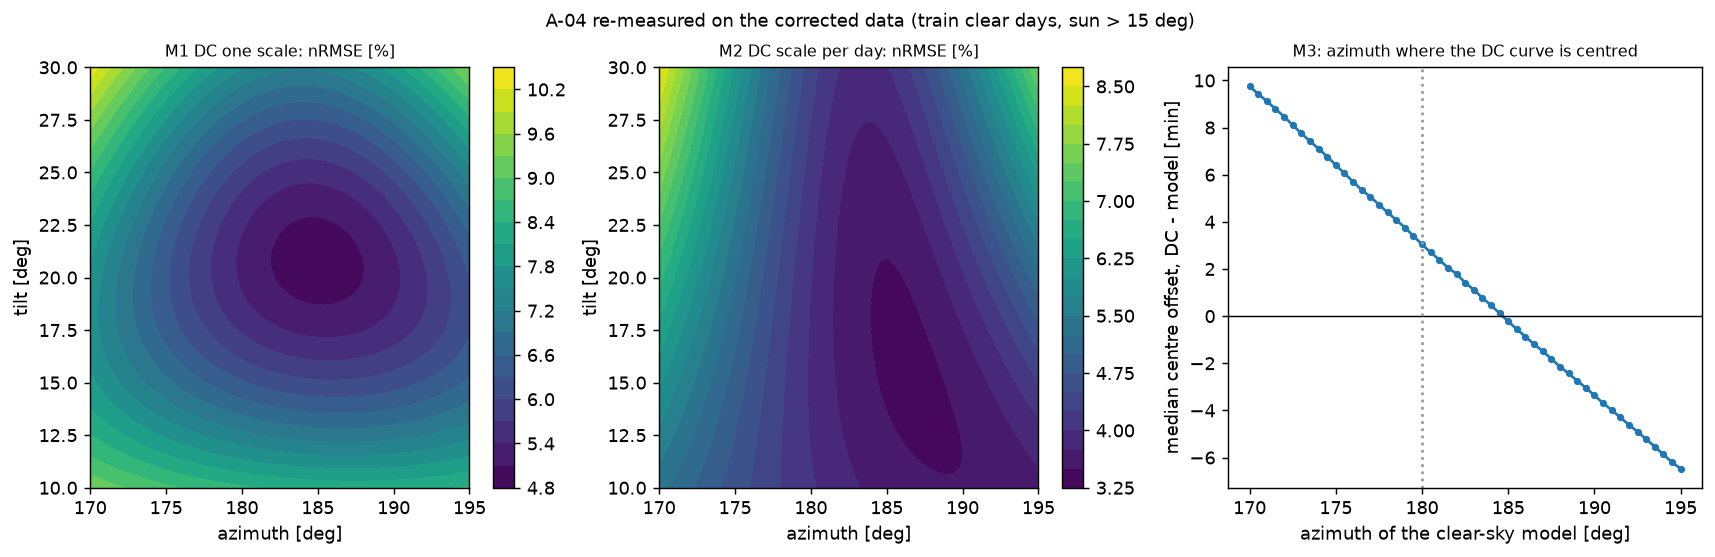

In [2]:
display(pd.read_csv(AUDIT_DIR / "orientation_2026-10-20" / "orientation_results.csv"))
display(Image(str(AUDIT_DIR / "orientation_2026-10-20" / "orientation_fit.png")))

**What it shows.** On 174 clear train days, temperature-corrected DC power
fits the clear-sky irradiance best on a plane of tilt 21° and azimuth
185° (one scale for all days), azimuth
186.5° from the daily shape alone, and
184.7° from the centre of the production
curve. The irradiance sensor, fitted the same way, faces 180.5°.

**What it means.** The panels face about 5° west of south. The sensor faces south, and the
earlier result of F-13 (180°) came from clocks that were still slow. Methods agree, and the
difference exceeds the 2° rule of the plan. **Decision (A-04, F-23):** the panel plane
21°/185° is used for the theoretical
power and the POA features. The clock correction keeps the sensor plane on which it was framed.
External confirmation (satellite row orientation or the operator) is still open (Q-11).

## 2. The target k and its denominator (D-11)

,denominator,hours,median,p99,share_above_1,share_above_1.2,share_exactly_1.2
0,ghi,9656,0.8663,1.4996,0.3245,0.1254,0.0
1,poa,9656,0.8165,1.1466,0.0544,0.0061,0.0


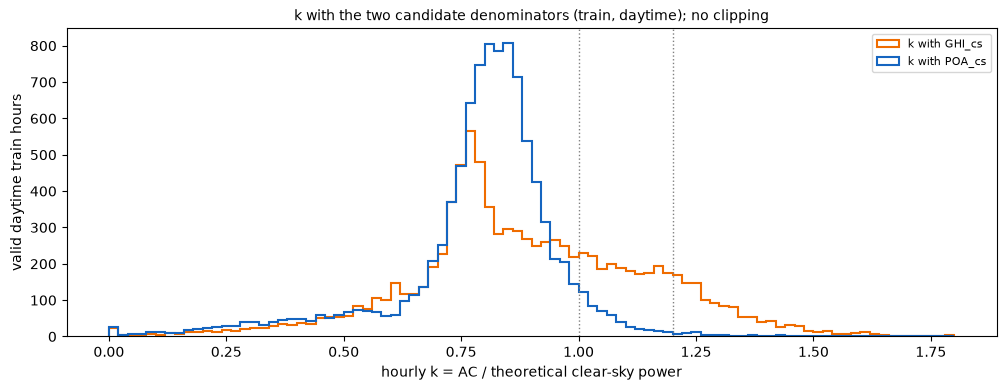

In [3]:
r = R.k_distributions(t1)
r.show()

**What it shows.** k = AC / theoretical clear-sky power on valid daytime train hours.
- **With GHI_cs:** 32.4 % of hours have k above 1, and
  12.5 % above 1.2.
- **With POA_cs on the panel plane:** 5.4 % and
  0.61 %.
- No value sits exactly at 1.2.
- 23 hours over all splits exceed 1.5 (`k_suspect`). All are
  at low sun (elevation 1.4–9.7°,
  theo at most 198.5 kW), and 0 are
  op-limited. Each is a ratio of two small numbers; the hours are flagged, not removed (§6.5).

**What it means.** k is not clipped (F-06 fixed). In the original, 16.8 % of daytime test hours
were cut at exactly 1.2. With the right reference, almost nothing is near that value, because
k > 1 is now rare instead of being an artefact of the reference.

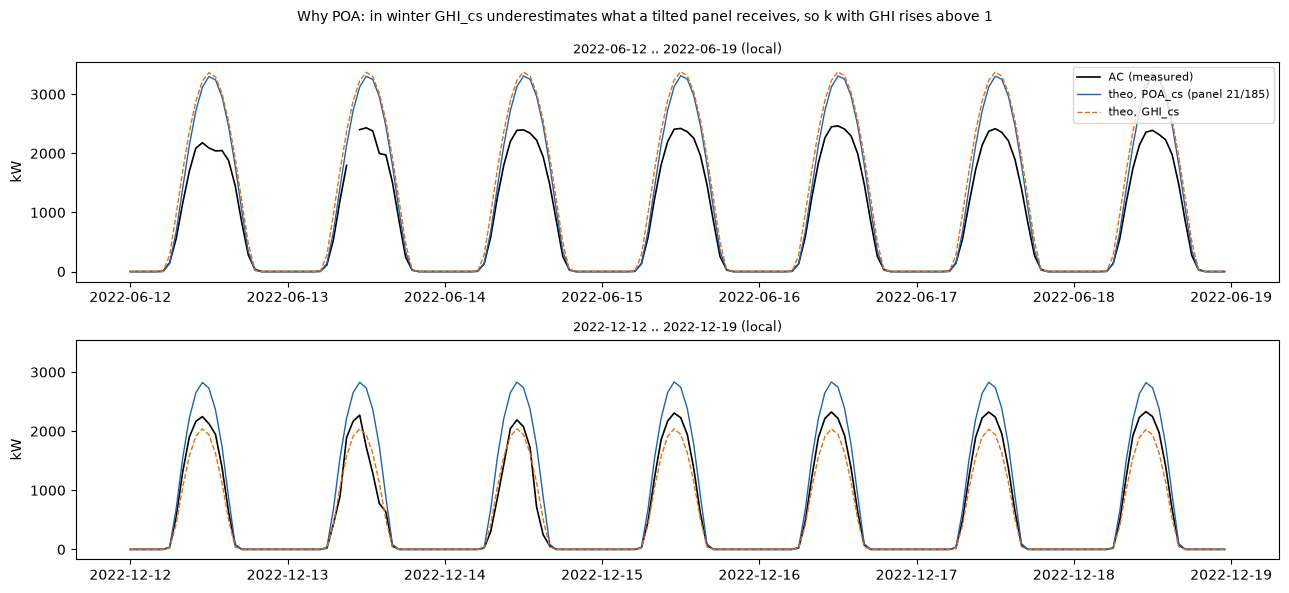

In [4]:
r = R.weeks(t1)
r.show()

**What it shows.** A clear summer week and a winter week: measured AC, and the
theoretical power with each reference.

**What it means.** In winter the sun is low and the panels are tilted towards it. A horizontal
reference (GHI_cs) underestimates what they receive, so measured AC exceeds it and k with GHI
rises above 1. The plane-of-array reference follows the panel geometry. In summer the two
references are close.

,denominator,share_k_above_1,share_k_above_1.2,clear_day_k_spread,clear_day_k_monthly_std,val_nrmse_kw_pct,val_nrmse_kw_seed_std
0,ghi,0.32446,0.12541,0.4127,0.1549,8.0931,0.0561
1,poa,0.05437,0.00611,0.1079,0.0335,7.9406,0.0878


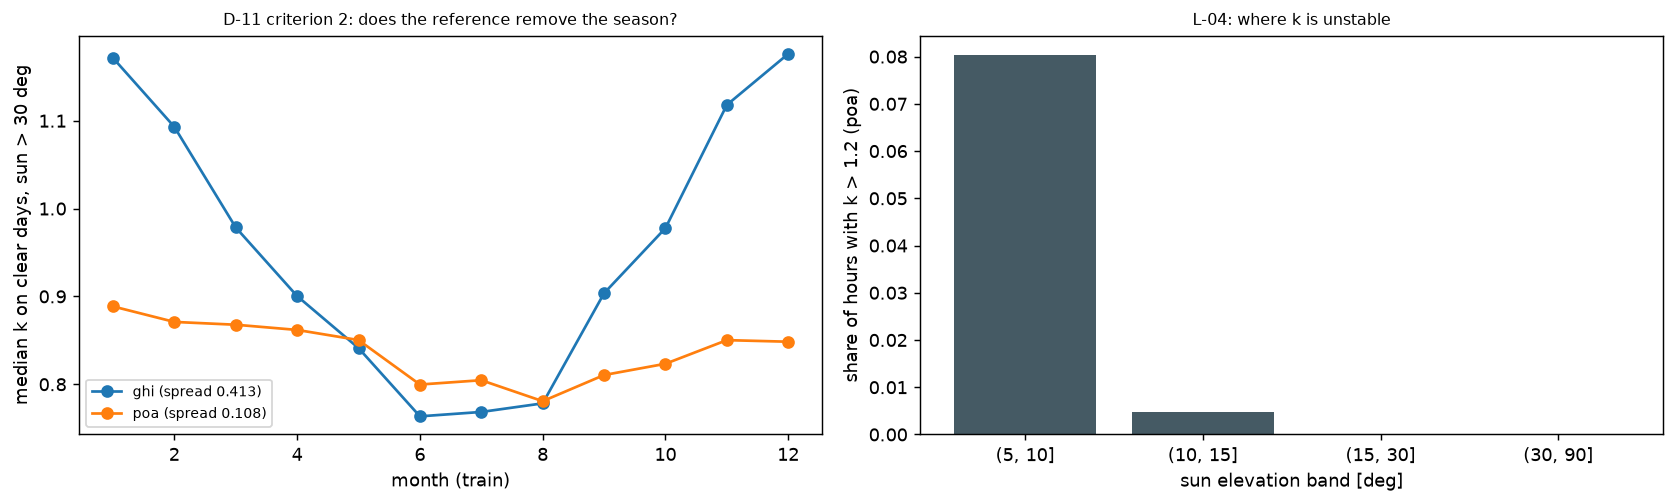

In [5]:
crit = pd.read_csv(OUTPUTS_DIR / "06_features" / "d11_criteria.csv")
display(crit)
display(Image(str(OUTPUTS_DIR / "06_features" / "d11_l04.png")))

**What it shows.** The three D-11 criteria, all fixed before they were computed:

| Criterion | GHI_cs | POA_cs |
|---|---|---|
| 1. share of k > 1 (train) | 32.4 % | 5.4 % |
| 2. spread of the monthly clear-day median k (train) | 0.413 | 0.108 |
| 3. validation nRMSE in kW (fixed XGBoost, 3 seeds) | 8.09 ± 0.06 % | 7.94 ± 0.09 % |

**Decision (D-11): POA_cs**, which wins
3 of 3 criteria. It removes the season from clear-day k almost
completely (criterion 2) and gives the lower error in kW (criterion 3). Validation was used only
for criterion 3, as specified.

## 3. Low sun (L-04, from the literature review)

In [6]:
display(pd.read_csv(OUTPUTS_DIR / "06_features" / "l04_k_by_elevation.csv"))
display(pd.read_csv(OUTPUTS_DIR / "06_features" / "l04_training_threshold.csv"))

,sun_elevation,hours,k_median,k_p99,share_k_above_1.2,share_k_above_1.5
0,"(5, 10]",684,0.9730,1.4249,0.0804,0.0058
1,"(10, 15]",830,0.8072,1.1263,0.0048,0.0000
2,"(15, 30]",2264,0.8546,1.0568,0.0000,0.0000
3,"(30, 90]",5878,0.7991,0.9719,0.0000,0.0000


,min_theo_kw,val_nrmse_kw_pct_mean,val_nrmse_kw_pct_seed_std
0,50.0,7.9406,0.0878
1,100.0,8.0572,0.0213
2,150.0,7.8874,0.0492


**What it shows.** k by sun elevation on train. Below that, the validation nRMSE in kW
when hours with a small theoretical power are left out of the training loss (3 seeds each):

| Threshold | nRMSE |
|---|---|
| 50 kW | 7.941 ± 0.088 % |
| 100 kW | 8.057 ± 0.021 % |
| 150 kW | 7.887 ± 0.049 % |

**What it means.** k is least stable at low sun, as the literature (C2) and stage 3b (Q22)
suggested. But leaving those hours out of the training loss does not help reliably.
- The best gain (150 kW) is 0.053 pp.
- The rule requires more than 0.119 pp: twice the seed-to-seed noise.
- 100 kW is worse than both.

**Decision: the training threshold stays 50 kW** (§6.5).

**A note on method.** The first rule (a gain of 0.05 pp on one fit) would have chosen 150 kW
from noise: on one seed, 100 kW was 0.18 pp worse and 150 kW 0.05 pp better. The rule was made
seed-robust *before* the threshold was adopted, and the change is recorded in the run journal
(R6-03, R6-04) and in `decide_k.py`.

In [7]:
derived = yaml.safe_load((CONFIGS_DIR / "derived_constants.yaml").read_text(encoding="utf-8"))
print(derived)
print(R.kw_from_k(t1))

{'mean_daytime_k': 0.788157, 'k_denominator': 'poa', 'panel_plane': {'tilt': 21.0, 'azimuth': 185.0}, 'source': 'python -m solarpv.features.build (stage 6)'}
{'max_abs_error_kw': 2.2737367544323206e-13, 'valid_hours': 15809, 'capacity_kw': 3449.0}


**What it shows.** `MEAN_DAYTIME_K` = 0.7882: the mean k over valid
daytime train hours, the denominator of the indirect nRMSE (§6.9). The inversion k × theo − AC
is at most 2.3e-13 kW over 15,809 valid hours (T-11).

**What it means.**
- The original's 0.6279 came from the clipped, wrongly timed k; it is kept only for the
  evaluation fixture (T-15).
- A forecast of k converts to kW exactly through the same theoretical power. The route
  comparison can therefore score both targets against actual AC (C-16).

## 4. Past-day features: issuance, DST, masks and gaps

In [8]:
from solarpv.config.constants import TIMEZONE_LOCAL
from solarpv.features import build as B

s = t1["site_total_AC_kW"]
guarded = pd.Series(B.past_value(s, 1, B.issuance_utc(t1.index, 1)), index=t1.index)
h = t1.loc["2022-10-30 19:00":"2022-10-30 23:00"].index  # around the end of the 25-hour day
src = h - pd.Timedelta(hours=24)
pd.DataFrame({
    "local time": h.tz_convert(TIMEZONE_LOCAL).strftime("%d.%m %H:%M %Z"),
    "T0 (UTC)": t1.loc[h, "t0_utc"].dt.strftime("%d.%m %H:%M").to_numpy(),
    "24 h back (UTC)": src.strftime("%d.%m %H:%M"),
    "source ended by T0": (src + pd.Timedelta(hours=1) <= t1.loc[h, "t0_utc"]).to_numpy(),
    "plain 24 h shift": s.shift(24).loc[h].to_numpy(),
    "lag_1d after the guard": guarded.loc[h].to_numpy(),
    "lag_1d in the table": t1.loc[h, "site_total_AC_kW_lag_1d"].to_numpy()},
    index=h.strftime("%d.%m %H:%M UTC"))

,local time,T0 (UTC),24 h back (UTC),source ended by T0,plain 24 h shift,lag_1d after the guard,lag_1d in the table
timestamp_utc,,,,,,,
30.10 19:00 UTC,30.10 21:00 IST,29.10 21:00,29.10 19:00,True,0.0,0.0,0.0
30.10 20:00 UTC,30.10 22:00 IST,29.10 21:00,29.10 20:00,True,0.0,0.0,0.0
30.10 21:00 UTC,30.10 23:00 IST,29.10 21:00,29.10 21:00,False,0.0,NaN,0.0
30.10 22:00 UTC,31.10 00:00 IST,30.10 22:00,29.10 22:00,True,0.0,0.0,0.0
30.10 23:00 UTC,31.10 01:00 IST,30.10 22:00,29.10 23:00,True,0.0,0.0,0.0


**What it shows.** The last hours of 30 October 2022 local, the day the clock falls
back (25 local hours), with the issuance time T0 of each row. For the 25th hour (23:00 local),
the hour 24 h earlier is 29.10 21:00 UTC. That is T0 itself, the first hour of the forecast day,
so its value is not known when the forecast is issued.

**What it means.**
- A plain 24-hour shift would read it. The guard turns it into NaN, and the imputation then
  fills it from earlier days.
- Over the four autumns the guard removes 28 values at D+1,
  56 at D+2 and 84 at D+3.
- At this site the 25th hour is at night, so the leaked value would have been 0 anyway. The
  guard keeps the rule exact rather than lucky.
- The perturbation tests (T-09, T-18) change every value from T0 on and check that no feature
  of the day moves.

,feature,imputed_share_D1,imputed_share_D2,imputed_share_D3
35,site_total_AC_kW_lag_14d,0.03564,0.03564,0.03564
34,site_total_AC_kW_lag_7d,0.03053,0.03053,0.03053
30,s01_inv2_AC_kW_lag_14d,0.02995,0.02995,0.02995
25,s01_inv1_AC_kW_lag_14d,0.02776,0.02776,0.02776
33,site_total_AC_kW_lag_3d,0.02761,0.02761,0.02797
32,site_total_AC_kW_lag_2d,0.02687,0.02712,0.00000
31,site_total_AC_kW_lag_1d,0.02627,0.00000,0.00000
29,s01_inv2_AC_kW_lag_7d,0.02484,0.02484,0.02484
24,s01_inv1_AC_kW_lag_7d,0.02264,0.02264,0.02264
28,s01_inv2_AC_kW_lag_3d,0.02191,0.02191,0.02228


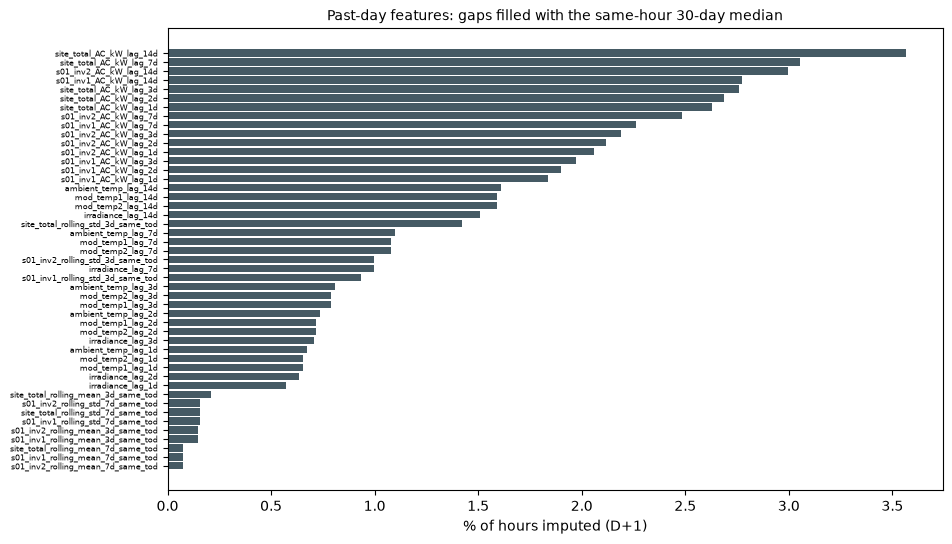

In [9]:
r = R.imputation(manifest)
r.show(rows=12)

**What it shows.** The share of imputed values per past-day feature at D+1 (at most
3.56 %).

**What it means.**
- **D-22 masks.** Before any lag, each inverter's AC is masked in the hours of its own stops,
  derates or curtailment: 474 and
  548 hours. The site total is masked in
  733 op-limited hours. A limitation is not weather,
  and must not teach the model that yesterday was cloudy.
- **Imputation.** The gaps are filled with the median of the same UTC hour over the previous 30
  days. The original used the median of the whole column, nights included.
- **Warm-up.** The first 14 days (336 hours) have too
  little history and are marked as warm-up, excluded from training.

In [10]:
d = pd.read_csv(OUTPUTS_DIR / "06_features" / "feature_dictionary.csv")
with pd.option_context("display.max_rows", 80, "display.max_colwidth", 120):
    display(d[["feature", "group", "definition", "unit", "horizons"]])

,feature,group,definition,unit,horizons
0,ghi_clearsky,clearsky,clear-sky global horizontal irradiance,W/m2,"1,2,3"
1,dhi_clearsky,clearsky,clear-sky diffuse horizontal irradiance,W/m2,"1,2,3"
2,dni_clearsky,clearsky,clear-sky direct normal irradiance,W/m2,"1,2,3"
3,sun_elevation,clearsky,apparent sun elevation (refraction corrected),deg,"1,2,3"
4,poa_global_clearsky,clearsky,"clear-sky irradiance on the panel plane, total (the k denominator, D-11)",W/m2,"1,2,3"
5,poa_direct_clearsky,clearsky,"clear-sky irradiance on the panel plane, direct beam",W/m2,"1,2,3"
6,poa_diffuse_clearsky,clearsky,"clear-sky irradiance on the panel plane, sky + ground diffuse",W/m2,"1,2,3"
7,poa_sky_diffuse_clearsky,clearsky,"clear-sky irradiance on the panel plane, sky diffuse",W/m2,"1,2,3"
8,poa_ground_diffuse_clearsky,clearsky,"clear-sky irradiance on the panel plane, ground reflected",W/m2,"1,2,3"
9,s01_inv1_rolling_mean_3d_same_tod,rolling_stats,"mean of inverter 1 AC power at the same UTC hour over 3 days, starting h days back",kW,"1,2,3"


**What it shows.** The feature dictionary: for each of the
74 features, its definition, unit and the horizons that use
it. The CSV also gives the method of each group, *why the feature is known at T0*, and the
imputed share at each horizon.

**What changed from the original:**
- `sun_azimuth` is gone: it equals `solar_azimuth` (Q-05).
- Solar noon comes from the computed transit, not "local hour − 12".
- `daylight_fraction` is computed from sunrise and sunset, not from an approximation.
- The weekend is Friday–Saturday (Israel), not Saturday–Sunday.
- The POA features use the measured panel plane, not 30°/180°.
- The rolling statistics follow the horizon, which fixes F-07.

## 5. A first look at what predicts k

,feature,spearman_r
0,poa_direct_clearsky,-0.4030
1,aoi,0.3984
2,poa_global_clearsky,-0.3981
3,dni_clearsky,-0.3906
4,poa_ground_diffuse_clearsky,-0.3730
5,ghi_clearsky,-0.3730
6,irradiance_lag_14d,-0.3704
7,irradiance_lag_7d,-0.3660
8,airmass,0.3616
9,irradiance_lag_3d,-0.3614


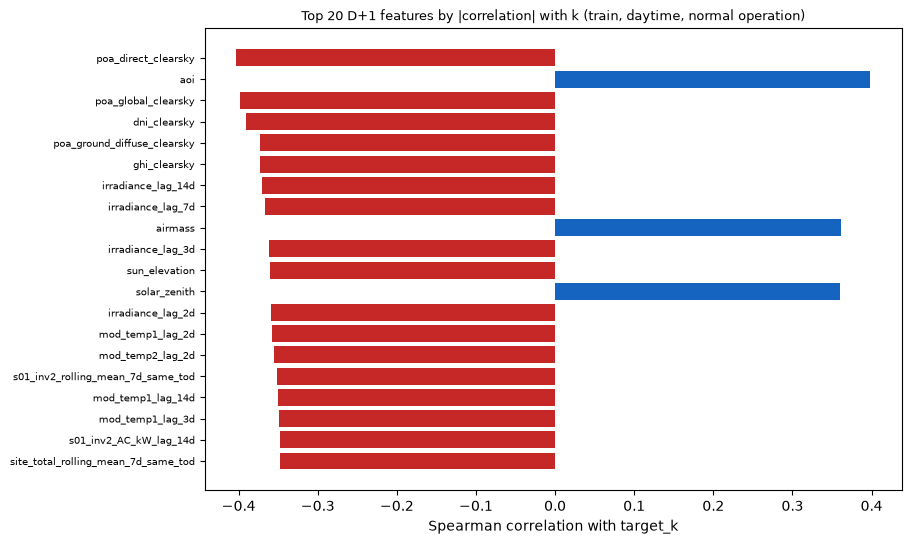

In [11]:
r = R.target_correlations(t1)
r.show(rows=10)

**What it shows.** Spearman correlation of each D+1 feature with k (train, daytime,
normal operation). The strongest are geometric: poa_direct_clearsky, aoi, poa_global_clearsky.

**What it means.**
- k is lower when the clear-sky irradiance on the panels is high (summer, midday) and higher
  when it is low (|r| about 0.4). Possible causes, not tested
  here: heat losses of the modules and the inverters at high irradiance, and the share of
  diffuse light at low sun, which the clear-sky model estimates least well. Even after dividing
  by the clear sky, geometry still carries information about k.
- Yesterday's *power* at the same hour correlates -0.28 with today's k.
  Power carries the daily and seasonal cycle that k removes.
- **Proposal for stage 7** (to be decided on validation, not part of the contract now): give the
  indirect route lags of k itself, which carry yesterday's sky condition without the cycle.
- In stage 3b the clear-sky index persisted only weakly from one day to the next (r =
  0.34, Q26). The weather forecasts of stage 6b are expected to
  carry most of the skill.

These are correlations on train, not causes; the choice of features belongs to stage 7.

## 6. Checks

In [12]:
print((AUDIT_DIR / "features_2026-10-20" / "mutation_check_output.txt").read_text())

caught      (a) rolling from shift 1 day at D+2 (F-07)
caught      (b) imputation with backward fill
caught      (b2) imputation from the same hour on later days
caught      (c) lags without the DST guard (25th hour)
caught      (c) lags without the DST guard (perturbation, D+1)
unmodified code passes



**What it shows.** Five deliberate leaks were planted in the feature code, and each was
caught by the tests:
- (a) the original's rolling window (F-07);
- (b) backward fill;
- (b2) a median from later days;
- (c) lags without the DST guard, in two forms.

The unmodified code passes the same tests.

**What it means.** The leakage tests do more than run: they detect the errors they are written
for. The first run of this check found two weak tests: the synthetic data had no gaps, and the
test window skipped the DST day. Both were fixed before this table was built.

## Summary

| Decision | Result |
|---|---|
| A-04, panel orientation | 21°/185° (panel plane; the sensor plane 20°/180° stays the clock frame) |
| D-11, k denominator | POA_cs: 3 of 3 criteria |
| L-04, low-sun threshold | stays 50 kW (no robust gain) |
| Q-05 | `sun_azimuth` removed; 74 features |
| MEAN_DAYTIME_K | 0.7882 (original 0.6279) |

**Next:** the evaluation layer reads truth and theoretical power from these tables (stage 8,
part B). Then the GFS forecasts (stage 6b), whose literature ideas (L-05–L-11) start there.

**Reproduce:** `python -m solarpv.features.build`, `python -m solarpv.features.decide_k`,
`python -m solarpv.features.build`, `python scripts/make_features_notebook.py`. Tests:
`pytest tests/unit/test_features_build.py tests/unit/test_target.py
tests/contracts/test_features_output.py`.